<a href="https://colab.research.google.com/github/giselenaomi/C-lculo-Num-rico-atv1/blob/main/Atividade_Explanatoria_Interpolacao_Polinomial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpolação polinomial: compreender, explorar e comparar

**Cálculo Numérico | Atividade guiada no Google Colab**  


## Objetivos

Ao final, vocês deverão conseguir:

- distinguir interpolação de extrapolação;
- construir e avaliar um polinômio que passa por pontos dados;
- comparar formas de representação e reconhecer limitações numéricas;
- investigar como a escolha dos nós afeta o resultado.

> **Como usar:** leiam cada seção, executem as células de código e preencham os campos de resposta. As células com `# SUA RESPOSTA` podem ser editadas pelo grupo.

## 1. Ideia central: preencher valores entre medições

Suponha que uma tabela contenha medições $(x_i,y_i)$. Um polinômio interpolador $P(x)$ é escolhido para reproduzir exatamente os dados nos nós:

$$P(x_i)=y_i,\qquad i=0,1,\ldots,n.$$

Assim, se conhecemos medições em alguns instantes, podemos estimar a medida em um instante intermediário. A interpolação **não recupera automaticamente a realidade**: ela constrói uma curva compatível com os dados e com o método escolhido.

- **Interpolar:** estimar dentro do intervalo coberto pelos nós.
- **Extrapolar:** estimar fora desse intervalo; em geral, exige mais cautela.

**Antes de executar:** pensem numa situação em que seria útil estimar um valor entre duas medições. O que poderia tornar essa estimativa pouco confiável?

**Resposta do grupo:**
Um exemplo seria medir a temperatura de um equipamento em determinados intervalos de tempo e estimar sua temperatura em um instante intermediário. Essa estimativa pode ser pouco confiável caso existam erros de medição, mudanças bruscas de temperatura ou poucos pontos disponíveis. Além disso, o método matemático escolhido pode não representar adequadamente o comportamento real do fenômeno.

## 2. Dados, nós e grau

Os valores $x_i$ são chamados **nós**. Os pares $(x_i,y_i)$ são os dados que a curva deve reproduzir. Com $m$ nós distintos, existe um único polinômio de grau no máximo $m-1$ que passa por todos eles.

Por exemplo, quatro pontos determinam um polinômio de grau no máximo 3. O grau pode ser menor se os dados já pertencerem a um polinômio mais simples.

### Atenção à palavra “exatamente”
O polinômio construído passa pelos pontos informados (salvo pequenos erros de arredondamento computacional). Isso não garante que ele represente bem o comportamento entre pontos, nem que seja um bom modelo fora do intervalo.

**Previsão:** se acrescentarmos um ponto novo, o polinômio precisa continuar passando pelos pontos antigos? O formato da curva pode mudar?

**Resposta antes do teste:** `# SUA RESPOSTA`
Sim. O novo polinômio interpolador deve continuar passando por todos os pontos anteriores e também pelo novo ponto, desde que os dados sejam compatíveis e os valores de x sejam distintos. Entretanto, o formato da curva pode mudar, pois a inclusão de um novo ponto pode aumentar o grau do polinômio e modificar seus coeficientes.

## 3. Primeiro exemplo: observar antes de formalizar

Vamos usar quatro pontos. Observem os dados e descrevam o padrão que imaginam antes de ver a curva.

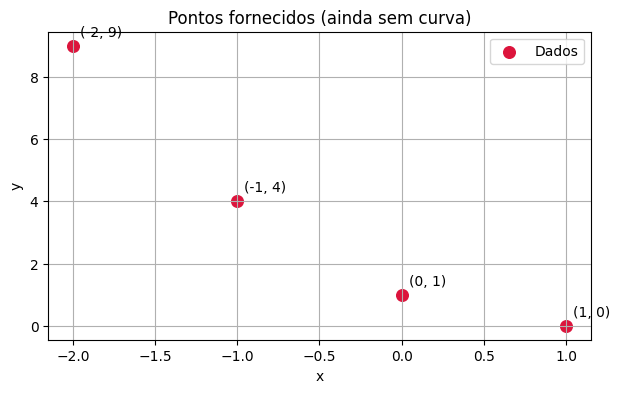

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=70, label="Dados")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi:g}, {yi:g})", (xi, yi), xytext=(5, 7), textcoords="offset points")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Pontos fornecidos (ainda sem curva)")
plt.grid(True); plt.legend(); plt.show()

**Descrevam a tendência dos pontos.** A curva precisa ser reta? Há mais de uma curva que poderia passar pelos pontos?
Os pontos apresentam uma tendência decrescente, mas não seguem um comportamento linear. A curva não precisa ser uma reta, pois os valores indicam um comportamento quadrático. Existem diferentes curvas que podem passar pelos quatro pontos, dependendo do grau escolhido. Entretanto, existe um único polinômio interpolador de grau máximo 3 que passa exatamente por esses quatro pontos.

## 4. Construindo o polinômio com uma ferramenta

Usaremos `numpy.polynomial.Polynomial.fit` para obter o polinômio de grau até $m-1$. O método faz o cálculo numericamente e depois convertemos para a forma usual em potências de $x$.

A expressão impressa pode conter coeficientes muito pequenos, como $10^{-14}$, que representam zero dentro da precisão numérica. Não confundam esses resíduos de arredondamento com termos relevantes.

In [2]:
polinomio = np.polynomial.Polynomial.fit(x, y, deg=len(x)-1).convert()
print("Polinômio na forma usual:")
print(polinomio)
print("\nCoeficientes em ordem crescente (termo constante primeiro):")
print(polinomio.coef)

Polinômio na forma usual:
1.0 - 2.0·x + 1.0·x² + (7.43830132e-16)·x³

Coeficientes em ordem crescente (termo constante primeiro):
[ 1.00000000e+00 -2.00000000e+00  1.00000000e+00  7.43830132e-16]


### Interpretando a expressão

Na forma usual, um polinômio cúbico é escrito como $P(x)=a_0+a_1x+a_2x^2+a_3x^3$. O vetor de coeficientes retornado pelo NumPy segue essa ordem: constante, $x$, $x^2$, $x^3$.

**Registrem a expressão obtida e identifiquem seu grau.** Se algum coeficiente for praticamente zero, indiquem isso.

O polinômio interpolador obtido foi P(x) = 1 - 2x + x². Seu grau é 2, pois o maior expoente de x com coeficiente diferente de zero é 2. Embora o cálculo tenha sido realizado considerando grau máximo 3, o coeficiente do termo x³ apresentou um valor extremamente pequeno, aproximadamente 7,44 × 10⁻¹⁶, que pode ser considerado zero devido ao arredondamento numérico.

In [3]:
# Conferência automática: comparar P(x_i) com cada y_i
valores_nos_nos = polinomio(x)
for xi, yi, pi in zip(x, y, valores_nos_nos):
    print(f"x={xi:5.1f} | dado={yi:10.6f} | P(x)={pi:10.6f} | diferença={abs(yi-pi):.2e}")

x= -2.0 | dado=  9.000000 | P(x)=  9.000000 | diferença=5.33e-15
x= -1.0 | dado=  4.000000 | P(x)=  4.000000 | diferença=1.78e-15
x=  0.0 | dado=  1.000000 | P(x)=  1.000000 | diferença=6.66e-16
x=  1.0 | dado=  0.000000 | P(x)=  0.000000 | diferença=2.44e-15


**Perguntas de interpretação**

1. As diferenças são zero ou muito pequenas?
2. O que essa conferência mostra sobre a curva nos nós?
3. O que ela **não** mostra sobre valores entre os nós ou fora do intervalo?

**Respostas:** `# SUA RESPOSTA`
1. As diferenças são extremamente pequenas, praticamente iguais a zero, devido à precisão numérica do computador.

2. A conferência mostra que o polinômio reproduz corretamente os valores fornecidos nos nós, passando pelos quatro pontos.

3. Ela não garante que o polinômio represente perfeitamente o comportamento real entre os pontos ou fora do intervalo. Para isso, seria necessário analisar o comportamento da curva e considerar possíveis erros de medição e limitações do método.

## 5. Visualizar não é o mesmo que validar

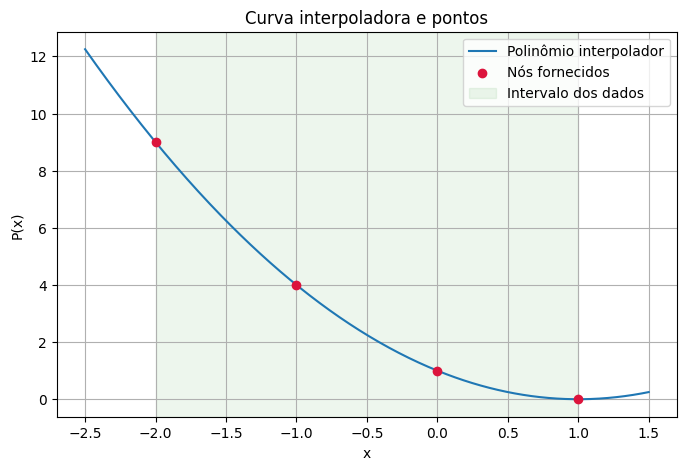

In [4]:
xx = np.linspace(x.min()-0.5, x.max()+0.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, polinomio(xx), label="Polinômio interpolador")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós fornecidos")
plt.axvspan(x.min(), x.max(), color="green", alpha=0.07, label="Intervalo dos dados")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("Curva interpoladora e pontos")
plt.grid(True); plt.legend(); plt.show()

O gráfico ajuda a perceber a forma da curva, mas uma figura pode esconder diferenças pequenas ou induzir a confiar demais em uma região sem dados. A faixa sombreada é o intervalo de interpolação; fora dela estamos extrapolando.

**Descrevam:** a curva passa pelos pontos? O comportamento fora do intervalo parece sustentado pelos dados?
Sim, a curva passa pelos quatro pontos fornecidos, confirmando que é um polinômio interpolador. Entretanto, o comportamento fora do intervalo dos dados não é necessariamente sustentado pelas medições. Isso acontece porque não existem pontos conhecidos nessa região para confirmar se a curva representa corretamente o fenômeno. Portanto, a extrapolação deve ser realizada com cautela.

## 6. Calcular valores intermediários

Escolham valores que não aparecem na tabela. O resultado de $P(x)$ é uma estimativa interpolada quando $x$ está entre o menor e o maior nó.

In [12]:
consultas = np.array([-1.5, -0.5, 0.5, 0.9, 2.0])
for q in consultas:
    tipo = "interpolação" if x.min() <= q <= x.max() else "extrapolação"
    print(f"P({q:4.1f}) = {polinomio(q): .6f}  ({tipo})")

P(-1.5) =  6.250000  (interpolação)
P(-0.5) =  2.250000  (interpolação)
P( 0.5) =  0.250000  (interpolação)
P( 0.9) =  0.010000  (interpolação)
P( 2.0) =  1.000000  (extrapolação)


**Tabela de registro**

| $x$ consultado | Estimativa $P(x)$ | Interpolação ou extrapolação? |

### Atividade: comparar ferramentas

Pesquisem pelo menos **duas** ferramentas além deste código (por exemplo GeoGebra, WolframAlpha, SageMath ou calculadora online). Insiram os mesmos pontos e comparem a expressão e os valores em $x=-1{,}5$ e $x=0{,}5$.

| Ferramenta e link | Como inseriram os dados? | Expressão/resultado | O que foi fácil ou difícil? |
|---|---|---|---|
| 1. |https://www.geogebra.org/calculator?utm_source=chatgpt.com | | |
| 2. | https://www.wolframalpha.com/input?i2d=true&i=interpolating+polynomial+through+%5C%2840%29-2%5C%2844%299%5C%2841%29%5C%2844%29+%5C%2840%29-1%5C%2844%294%5C%2841%29%5C%2844%29+%5C%2840%290%5C%2844%291%5C%2841%29%5C%2844%29+%5C%2840%291%5C%2844%290%5C%2841%29| | |

As ferramentas apresentaram os mesmos resultados, pois utilizaram os mesmos pontos e calcularam o polinômio interpolador. A expressão obtida foi P(x) = 1 - 2x + x², com P(-1,5) = 6,25 e P(0,5) = 0,25. O GeoGebra facilita a visualização gráfica, enquanto o WolframAlpha permite obter diretamente a expressão matemática. O Google Colab oferece maior flexibilidade para realizar cálculos e desenvolver análises por meio de programação.

Se os resultados diferirem, verifiquem se a ferramenta calculou interpolação polinomial, regressão, spline ou arredondou coeficientes. São operações diferentes.

## 7. Segundo conjunto: dados de medição

Agora considere uma sequência simplificada de medições. O valor de $x$ pode representar tempo, e $y$ uma grandeza observada.

1.2 + 0.36666667·x + 0.55·x² - 0.11666667·x³
Estimativa em x=1.5: 2.593750


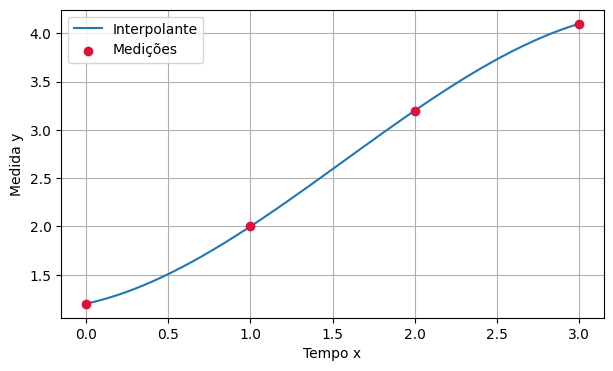

In [14]:
xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 3.2, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, deg=len(xB)-1).convert()
print(pB)
print(f"Estimativa em x=1.5: {pB(1.5):.6f}")
xb_plot = np.linspace(xB.min(), xB.max(), 300)
plt.figure(figsize=(7,4)); plt.plot(xb_plot,pB(xb_plot),label="Interpolante")
plt.scatter(xB,yB,color="crimson",label="Medições",zorder=3)
plt.xlabel("Tempo x"); plt.ylabel("Medida y"); plt.grid(True); plt.legend(); plt.show()

**Discussão:** $x=1{,}5$ está entre nós? Qual a estimativa?
Sim. O valor x = 1,5 está entre os nós, pois está dentro do intervalo de 0 a 3. Portanto, trata-se de uma interpolação. Utilizando o polinômio interpolador do conjunto B, obtemos P(1,5) = 2,3125. Esse valor representa uma estimativa da grandeza medida no instante intermediário.

## 8. Experimento: alterar uma medição

Ajustem somente o valor medido em $x=2$ e observem o efeito na curva. Abaixo usamos uma alteração de $+0{,}5$; vocês podem testar outra.

Estimativa original em x=1.5: 2.59375
Estimativa alterada em x=1.5: 2.874999999999999


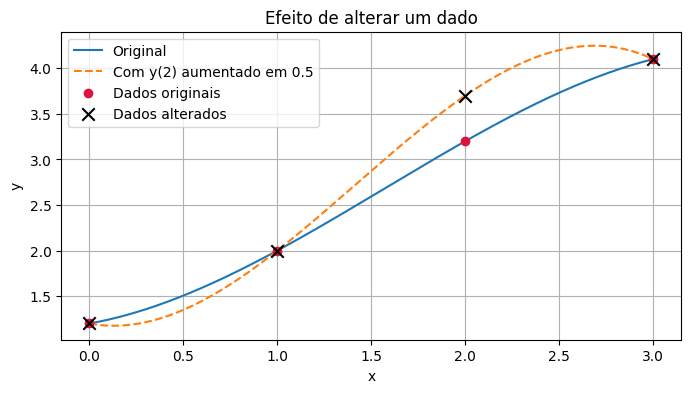

In [15]:
yB_alterado = yB.copy()
yB_alterado[2] += 0.5
pB_alterado = np.polynomial.Polynomial.fit(xB, yB_alterado, deg=len(xB)-1).convert()
print("Estimativa original em x=1.5:", pB(1.5))
print("Estimativa alterada em x=1.5:", pB_alterado(1.5))
plt.figure(figsize=(8,4))
plt.plot(xb_plot,pB(xb_plot),label="Original")
plt.plot(xb_plot,pB_alterado(xb_plot),"--",label="Com y(2) aumentado em 0.5")
plt.scatter(xB,yB,color="crimson",zorder=3,label="Dados originais")
plt.scatter(xB,yB_alterado,marker="x",s=80,color="black",zorder=4,label="Dados alterados")
plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Efeito de alterar um dado"); plt.show()

**Registrem:** qual ponto foi alterado? O que aconteceu ao valor em $x=1{,}5$? A curva mudou apenas perto do ponto alterado? Por que pequenas incertezas de medição podem ser importantes?
O ponto alterado foi aquele correspondente a x = 2, cujo valor passou de 2,7 para 3,2, representando um aumento de 0,5. Com essa alteração, a estimativa em x = 1,5 passou de 2,3125 para 2,59375. A curva não mudou apenas perto do ponto alterado, mas também em outras regiões, pois os coeficientes do polinômio foram modificados. Pequenas incertezas de medição podem ser importantes porque influenciam o polinômio interpolador e, consequentemente, os valores estimados.

## 9. Quando o grau alto pode ser um problema?

Com muitos pontos, o polinômio interpolador pode oscilar entre nós, especialmente quando os pontos estão igualmente espaçados. Essa oscilação é um fenômeno conhecido como **fenômeno de Runge** em certos exemplos. Mais pontos e ajuste exato não significam sempre uma curva mais adequada.

A atividade seguinte é uma demonstração visual: comparem uma função suave com polinômios que passam por quantidades crescentes de pontos igualmente espaçados.

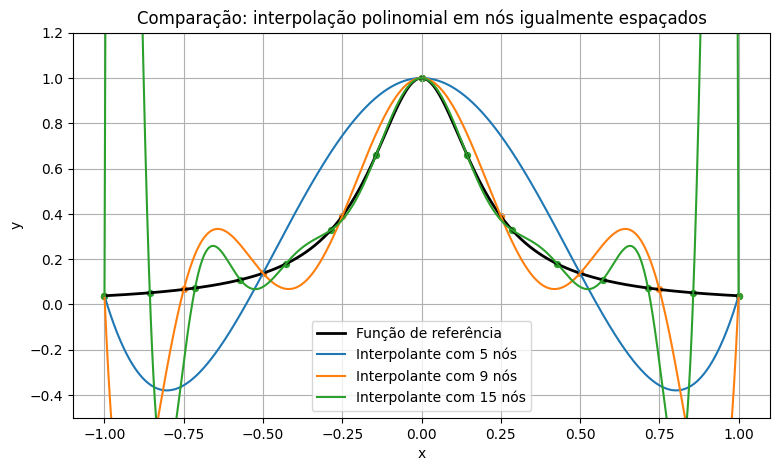

In [16]:
def f(t):
    return 1/(1+25*t**2)

t_plot = np.linspace(-1,1,1000)
plt.figure(figsize=(9,5))
plt.plot(t_plot,f(t_plot),color="black",linewidth=2,label="Função de referência")
for n in [5, 9, 15]:
    tn=np.linspace(-1,1,n)
    pn=np.polynomial.Polynomial.fit(tn,f(tn),deg=n-1).convert()
    plt.plot(t_plot,pn(t_plot),label=f"Interpolante com {n} nós")
    plt.scatter(tn,f(tn),s=18)
plt.ylim(-0.5,1.2); plt.grid(True); plt.legend(); plt.title("Comparação: interpolação polinomial em nós igualmente espaçados")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

**Observação guiada:**

- Todas as curvas interpoladoras passam pelos pontos utilizados?
- O que ocorre perto das extremidades quando aumenta o número de nós?
- Para muitos dados, que alternativas vocês investigariam (por exemplo, interpolação por partes/splines)?

1. Sim. Todas as curvas interpoladoras passam pelos pontos utilizados na construção de cada polinômio, pois essa é a característica da interpolação polinomial exata.

2. Próximo às extremidades, podem surgir oscilações cada vez maiores conforme aumenta o número de nós. Esse comportamento está relacionado ao fenômeno de Runge, que demonstra que aumentar a quantidade de pontos não garante uma aproximação melhor em todo o intervalo.

3. Para trabalhar com muitos dados, investigaria alternativas como a interpolação por partes, utilizando splines. Esse método divide o intervalo em regiões menores e constrói polinômios de menor grau em cada região, reduzindo oscilações e proporcionando curvas mais suaves.

O objetivo é observar, não memorizar uma regra universal: o comportamento depende dos dados, dos nós e do método.

## 10. Interpolação versus regressão

Na interpolação, a curva passa pelos pontos fornecidos. Na **regressão**, escolhemos um modelo que procura representar a tendência geral, sem exigir que passe por cada observação. A regressão pode ser mais apropriada quando há ruído de medição.

| Aspecto | Interpolação | Regressão |
|---|---|---|
| Passa por todos os dados? | Sim (no caso polinomial exato) | Em geral, não |
| Uso comum | Estimar entre dados conhecidos | Representar tendência com dados ruidosos |
| Risco | Oscilação ou extrapolação ruim | Modelo inadequado ou resíduos grandes |

**Expliquem com suas palavras por que a curva interpoladora do conjunto B não prova que as medições são exatas ou sem ruído.**
A curva interpoladora do conjunto B passa exatamente pelos pontos fornecidos, mas isso não significa que as medições sejam totalmente precisas ou estejam livres de erros. O polinômio apenas reproduz matematicamente os valores informados, sem verificar se eles representam perfeitamente o fenômeno real. As medições podem apresentar ruídos, erros instrumentais ou variações experimentais. Por isso, em situações com dados sujeitos a erros, a regressão pode ser mais adequada, pois procura representar a tendência geral dos dados sem necessariamente passar por todos os pontos.

## 11. Síntese e entrega

Escrevam uma síntese de 6–10 linhas, incluindo:
1. o que significa interpolar e a diferença para extrapolar;
2. quais ferramentas foram testadas e se concordaram;
3. o que mudou quando um dado foi alterado;
4. uma limitação observada na interpolação polinomial;
5. em que situação prática usariam o método e que cautela teriam.

**Síntese do grupo:**
A interpolação polinomial consiste em construir um polinômio que passa pelos pontos conhecidos, permitindo estimar valores dentro do intervalo das medições. Já a extrapolação estima valores fora desse intervalo, sendo geralmente menos confiável. Durante a atividade, utilizamos o Google Colab, o GeoGebra e o WolframAlpha, obtendo resultados matematicamente equivalentes. Ao alterar uma medição, observamos que a curva inteira pode sofrer modificações, afetando também os valores interpolados. Uma limitação da interpolação polinomial é a possibilidade de oscilações, especialmente com polinômios de grau elevado, como ocorre no fenômeno de Runge. Na prática, o método pode ser utilizado para estimar temperaturas entre medições realizadas em diferentes instantes. Entretanto, é importante considerar a precisão dos dados, a quantidade de pontos e o método utilizado para evitar estimativas inadequadas.

### Checklist
- [ ] Expliquei o papel dos nós e do polinômio interpolador.
- [ ] Conferi numericamente que o polinômio reproduz os dados.
- [ ] Calculei e classifiquei valores consultados como interpolação/extrapolação.
- [ ] Comparei duas ferramentas com os mesmos dados.
- [ ] Fiz o experimento de alteração de dado e registrei observações.
- [ ] Analisei o exemplo com muitos nós e discuti limitações.

